# Dalili destination model: a pretrained language model, fine-tuned by distillation

Dalili suggests destinations each traveller is likely to enjoy. This notebook walks through the model behind it:

1. **Data**: the Wikivoyage guides of 227 destinations, cleaned and cut into passages (place and country names masked).
2. **Teacher**: gpt-5-mini reads every guide and writes what kind of place it is and how central each interest is.
   The hand labels are never shown to it - they are only used to measure.
3. **Student**: MiniLM (`all-MiniLM-L6-v2`, 22M parameters), fine-tuned so its vectors carry the teacher's understanding.
4. **Export**: ONNX, int8 (23 MB) - the exact model the website runs with ONNX Runtime.
5. **Evaluation** on test destinations the training never tuned on, next to the model before fine-tuning, the teacher,
   a TF-IDF baseline and random.

The same code runs in the website: `travel_agent/recommender/` (`finetune.py` trains, `encoder.py` + `engine.py` serve).
Training takes about an hour on a laptop CPU, so this notebook loads the trained model by default (`TRAIN = False`).

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

ROOT = Path.cwd().parent if Path.cwd().name == "ml" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from travel_agent.recommender import catalog, corpus, evaluate, finetune
from travel_agent.recommender.catalog import INTERESTS
from travel_agent.recommender.encoder import Encoder

TRAIN = False   # True: teacher (cached) -> fine-tune -> ONNX -> evaluate (about an hour on a CPU)
report = ThreadPoolExecutor(1).submit(finetune.main).result() if TRAIN else json.loads(finetune.REPORT_PATH.read_text(encoding="utf-8"))
saved = np.load(finetune.MODEL_PATH, allow_pickle=False)
print(report["model"]); print("trained", report["trained_at"], "config", report["config"])

sentence-transformers/all-MiniLM-L6-v2 fine-tuned by distillation from gpt-5-mini (ONNX int8)
trained 2026-10-21T22:42:03+00:00 config {'steps': 500, 'lr': 5e-05, 'batch': 16, 'tau': 0.05, 'passage_len': 128, 'query': 'words', 'seed': 7}


## 1. Data
Only the sections that describe a place are kept (Understand, See, Do, Buy, Eat, Drink). Place and country names become *the place* / *the country*, so two places are alike for what they are, not for sharing a country. Each guide is cut into passages of about 180 words.

In [2]:
from concurrent.futures import ThreadPoolExecutor  # Jupyter already runs an event loop: load in a thread
dests, texts, passages, tokens, skipped = ThreadPoolExecutor(1).submit(finetune.load).result()
val, test = evaluate.split(dests)
print(f"{len(dests)} destinations ({len(val)} validation / {len(test)} test), {sum(map(len, passages)):,} passages; skipped {skipped}")
i = [d.id for d in dests].index("santorini")
print("\nSantorini, passage 1:\n", passages[i][0][:600], "...")

227 destinations (112 validation / 115 test), 5,044 passages; skipped ['St. Anton am Arlberg']

Santorini, passage 1:
 the place is an archipelago of 5 volcanic islands in the Cyclades group of the Greek islands in the southern Aegean Sea, about 200 km southeast of mainland the country. It used to be a single island, but was obliterated around 1600 BCE by an enormous volcanic explosion that destroyed the earliest settlements on the former island and created the current geological caldera. It is famous for dramatic views, stunning sunsets from white clifftop villages, the ancient city ruins of Thera and Akrotiri, unique wines, artists and craftsmen, an active volcano, and strikingly colorful pebble beaches. Und ...


## 2. The teacher
gpt-5-mini read each guide (`ml/dataset/teacher.jsonl`). How good is the teacher itself, measured against the hand labels? (This is the ceiling the student is learning towards.)

In [3]:
teacher = {r["id"]: r for r in map(json.loads, finetune.TEACHER_PATH.read_text(encoding="utf-8").splitlines())}
print(json.dumps(teacher["santorini"], indent=1, ensure_ascii=False))
print("\nteacher on the test split:", report["test"]["interests"]["teacher"], "| similar places P@5:",
      report["test"]["similar_places_p@5"]["teacher"])

{
 "id": "santorini",
 "description": "This volcanic island group is defined by a dramatic flooded caldera, steep cliffside villages of whitewashed buildings, and stark volcanic beaches and formations. Trips are about scenic vistas and sunsets, relaxed seaside stays with local wines and crafts, and active exploration—hiking crater rims, visiting archaeological sites and short boat trips to volcanic islets.",
 "interests": {
  "beach": 2,
  "culture": 2,
  "history": 3,
  "nature": 3,
  "ski": 0,
  "food": 2,
  "nightlife": 1,
  "shopping": 1,
  "relax": 3,
  "adventure": 2
 }
}

teacher on the test split: {'map': 0.776, 'p@10': 0.81} | similar places P@5: 0.699


## 3. Fine-tuning (distillation)

Each step takes 16 places (2 passages each) and fine-tunes the student with three soft objectives - soft, so that two
beach islands are never pushed apart as if they were opposites:

| Objective | Pulls together | Target |
|---|---|---|
| passages ↔ descriptions | a place's passages and the teacher's description of it | the teacher's similarity of the places in the batch (the place itself highest) |
| place ↔ place | places in the batch | the teacher's similarity |
| interest → places | each interest's words and the places | how central the teacher says that interest is at each place |

AdamW, linear warm-up and decay, temperature 0.05. The number of steps and how an interest is written (its seed words,
or "a destination for beach: ...") were chosen on the **validation** split.

tuning on validation:
  300 steps, lr 5e-05 phrase -> {'sim_p@5': 0.654, 'map': 0.726, 'p@10': 0.77}
  500 steps, lr 5e-05 words -> {'sim_p@5': 0.643, 'map': 0.751, 'p@10': 0.77}


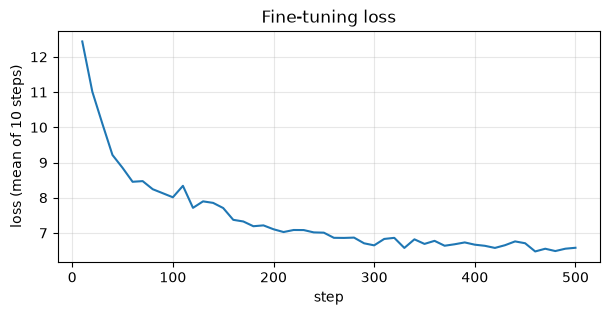

In [4]:
print("tuning on validation:")
for t in report["tuning"]:
    print(" ", t["config"]["steps"], "steps, lr", t["config"]["lr"], t["config"]["query"], "->", t["validation"])
curve = report["loss_curve"]
plt.figure(figsize=(7, 3)); plt.plot(np.arange(1, len(curve) + 1) * 10, curve)
plt.xlabel("step"); plt.ylabel("loss (mean of 10 steps)"); plt.title("Fine-tuning loss"); plt.grid(alpha=.3); plt.show()

## 4. Evaluation (test destinations only)
- **Similar places, Precision@5**: are a place's 5 nearest neighbours the same kind of place?
- **Interests, MAP**: rank the places for each interest; are the labelled ones on top?

The numbers are for the exported int8 ONNX model - the one the website runs.

                           similar P@5  interest MAP    P@10
Our model (fine-tuned)           0.624         0.738   0.770
Before fine-tuning               0.546         0.614   0.640
Teacher: gpt-5-mini              0.699         0.776   0.810
TF-IDF baseline                  0.518         0.599   0.600
Random                           0.278         0.248     nan


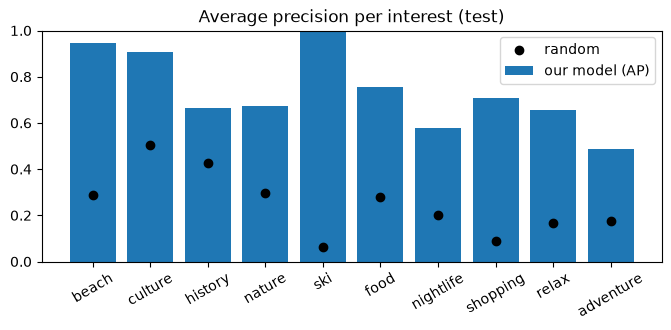

In [5]:
t = report["test"]
rows = [("Our model (fine-tuned)", "model"), ("Before fine-tuning", "pretrained"), ("Teacher: gpt-5-mini", "teacher"),
        ("TF-IDF baseline", "tfidf"), ("Random", "random")]
print(f"{'':26}{'similar P@5':>12}{'interest MAP':>14}{'P@10':>8}")
for label, k in rows:
    i = t["interests"][k]
    print(f"{label:26}{t['similar_places_p@5'][k]:>12.3f}{i['map']:>14.3f}{i.get('p@10', float('nan')):>8.3f}")
per = report["test_per_interest"]
plt.figure(figsize=(8, 3)); names = list(per)
plt.bar(names, [per[n]["ap"] for n in names], label="our model (AP)")
plt.scatter(names, [per[n]["random_p"] for n in names], color="k", zorder=3, label="random")
plt.xticks(rotation=30); plt.ylim(0, 1); plt.legend(); plt.title("Average precision per interest (test)"); plt.show()

## 5. The served model reproduces these vectors
The website embeds a city with ONNX Runtime from its guide. For a catalog city that must give the vector saved here (cosine ≈ 1).

In [6]:
enc = Encoder()
X, ids = saved["X"], saved["ids"].tolist()
for name in ("zermatt", "kyoto"):
    k = [d.id for d in dests].index(name)
    v = enc.place(passages[k])
    print(name, "cosine to the saved vector:", round(float(v @ X[ids.index(name)]), 5))

zermatt cosine to the saved vector: 1.0


kyoto cosine to the saved vector: 1.0


## 6. Examples
Nearest neighbours, and what each place is known for (its most distinctive guide words).

In [7]:
names, kw = saved["names"].tolist(), saved["keywords"].tolist()
for name in ("Kyoto", "Borovets", "Santorini", "Hurghada", "Marrakesh"):
    if name not in names: continue
    i = names.index(name)
    near = [names[j] for j in np.argsort(-(X @ X[i])) if j != i][:4]
    print(f"{name:10} -> {', '.join(near)}   | known for: {kw[i]}")
Q = saved["Q"]
for interest in ("beach", "ski", "nightlife"):
    top = [names[j] for j in np.argsort(-(X @ Q[INTERESTS.index(interest)]))[:5]]
    print(f"\ntop for {interest}: {', '.join(top)}")

Kyoto      -> Tokyo, Osaka, Taipei, Chiang Mai   | known for: shrine imperial blossom cherry
Borovets   -> Bansko, Aspen, Whistler, Zermatt   | known for: ski skiing hut boris
Santorini  -> Rhodes, Crete, Sicily, Tenerife   | known for: caldera volcanic eruption archipelago
Hurghada   -> Sharm El Sheikh, Jeddah, Dahab, Abu Dhabi   | known for: kite coral nile reef

top for beach: Algarve, Seychelles, Zanzibar, Fiji, Maldives

top for ski: Bansko, Aspen, Borovets, Dolomites, Zermatt

top for nightlife: Milan, New York City, Buenos Aires, Miami, Santiago


## 7. The taste map
All place vectors projected to 2-D (PCA), coloured by their main hand label. The dashboard draws the same map with the user's taste as a star.

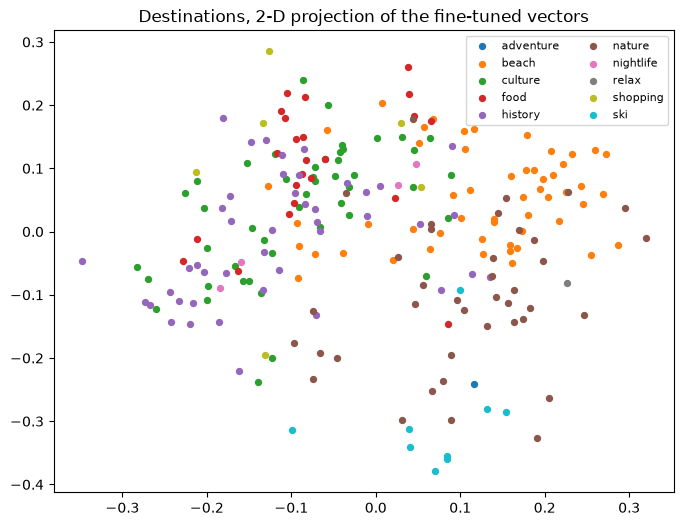

In [8]:
pts, tags = saved["pca_points"], [t.split()[0] for t in saved["tags"].tolist()]
plt.figure(figsize=(8, 6))
for tag in sorted(set(tags)):
    m = np.array([x == tag for x in tags])
    plt.scatter(pts[m, 0], pts[m, 1], s=18, label=tag)
plt.legend(ncol=2, fontsize=8); plt.title("Destinations, 2-D projection of the fine-tuned vectors"); plt.show()